# Week 1 — Titanic Survival Prediction: Data Cleaning & Preprocessing

## 1. Project Overview
**Objective:** The goal of this project is to perform essential data cleaning and preprocessing on the Titanic dataset.
**Dataset:** The dataset used is `titanic.csv`, containing information about passengers aboard the RMS Titanic, including their survival status.
**What is being demonstrated:** This notebook demonstrates the application of Machine Learning fundamentals from Week 1, specifically focusing on data handling, cleaning, imputation, encoding, and exploratory visualization.
**Expected outcome:** A clean, preprocessed dataset (`titanic_cleaned.csv`) ready for machine learning modeling, along with documented steps explaining each transformation.


## 2. Learning Objectives
This notebook demonstrates:
- Dataset loading
- Exploratory inspection
- Statistical analysis
- Missing-value handling
- Categorical encoding
- Basic visualization
- Data preprocessing
- Exporting a cleaned dataset


## 3. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# Set plot style
sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)


## 4. Load the Dataset
Loading the `titanic.csv` dataset and performing an initial inspection of its structure.
- **`head()`**: Displays the first 5 rows to give a sense of the data.
- **`shape`**: Shows the total number of rows and columns.
- **`columns`**: Lists all available column names.


In [2]:
# Load the raw dataset
df = pd.read_csv("titanic.csv")

# Display first 5 rows
display(df.head())

# Display shape
print(f"Dataset Shape: {df.shape}")

# Display columns
print(f"Columns: {df.columns.tolist()}")


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Dataset Shape: (891, 12)
Columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


## 5. Dataset Information
Using `.info()` and `.describe()` to understand data types, non-null counts, and basic statistical distributions of numerical features.
- **`info()`**: Helps identify object (categorical) vs numerical columns and preliminary missing data.
- **`describe()`**: Provides mean, min, max, and quartiles for numerical features.


In [3]:
print("Dataset Information:")
df.info()


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
print("Statistical Summary (Numerical Columns):")
display(df.describe())


Statistical Summary (Numerical Columns):


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
print("Data Types:")
display(df.dtypes)


Data Types:


PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

## 6. Missing-Value Analysis
Identifying which columns contain missing (null) values and calculating the percentage of missing data per column.
This step is crucial because most machine learning algorithms cannot handle missing values natively.


In [6]:
# Calculate missing values
missing_counts = df.isnull().sum()
missing_percentage = (missing_counts / len(df)) * 100

# Create a summary DataFrame
missing_summary = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_percentage
})

# Filter only columns with missing values and sort
missing_summary = missing_summary[missing_summary['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)
display(missing_summary)


,Missing Count,Missing Percentage (%)
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467


## 7. Duplicate Check
Checking for exact duplicate rows in the dataset to ensure each observation is unique.


In [7]:
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

if duplicates > 0:
    df = df.drop_duplicates()
    print(f"Removed {duplicates} duplicate rows. New shape: {df.shape}")
else:
    print("No duplicate rows found.")


Number of duplicate rows: 0
No duplicate rows found.


## 8. Numerical Data Analysis
Identifying numerical features vs identifiers.
- **Identifier**: `PassengerId` is a unique identifier and holds no predictive value.
- **Features**: `Age`, `Fare`, `SibSp`, `Parch`, `Pclass` are numerical features.
- **Target**: `Survived` is our target variable (binary).


## 9. Mean and Median Imputation
Handling missing values in numerical columns. The `Age` column has a significant number of missing values.
We will inspect the distribution of `Age` to decide whether to use Mean or Median imputation.
- **Mean** is sensitive to outliers.
- **Median** is robust against outliers and skewed data.


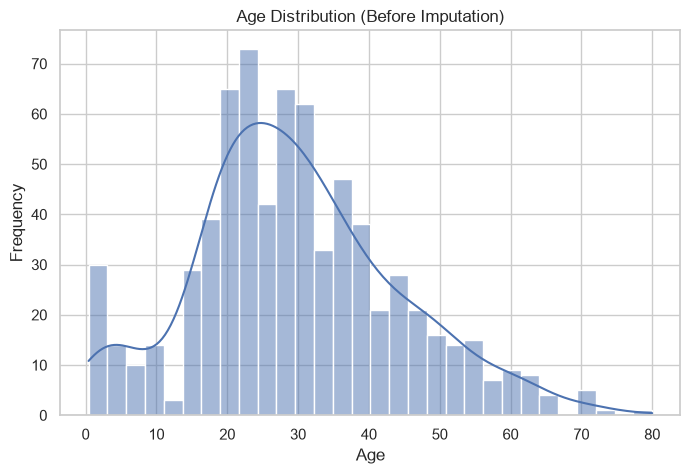

In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Age"].dropna(), kde=True, bins=30)
plt.title("Age Distribution (Before Imputation)")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()


The `Age` distribution is slightly right-skewed. To avoid the influence of potential extreme values (e.g., very elderly passengers), **Median imputation** is more appropriate than Mean imputation.


In [9]:
# Median Imputation for Age
age_median = df["Age"].median()
df["Age"] = df["Age"].fillna(age_median)

print(f"Filled missing Age values with median: {age_median}")


Filled missing Age values with median: 28.0


## 10. Categorical Missing Values
Handling missing values for categorical columns: `Cabin` and `Embarked`.
- **`Cabin`**: Has a very high percentage of missing values (over 70%). Imputing this would introduce significant bias, so we will drop this column.
- **`Embarked`**: Has only 2 missing values. We can safely impute these using the mode (most frequent value).


In [10]:
# Drop Cabin column due to excessive missing data
if 'Cabin' in df.columns:
    df = df.drop(columns=['Cabin'])
    print("Dropped 'Cabin' column.")

# Impute Embarked with the mode
if df['Embarked'].isnull().sum() > 0:
    embarked_mode = df['Embarked'].mode()[0]
    df['Embarked'] = df['Embarked'].fillna(embarked_mode)
    print(f"Filled missing Embarked values with mode: '{embarked_mode}'")


Dropped 'Cabin' column.
Filled missing Embarked values with mode: 'S'


## 11. Label Encoding
Machine learning models require numerical input. Label Encoding converts categorical labels into numeric form.
We apply this to the `Sex` column because it is a binary categorical variable (`male`/`female`).


In [11]:
print("Categories in 'Sex' before encoding:")
print(df['Sex'].unique())

label_encoder = LabelEncoder()
df['Sex'] = label_encoder.fit_transform(df['Sex'])

print("\nCategories in 'Sex' after encoding (0=female, 1=male based on alphabetic order):")
print(df['Sex'].unique())


Categories in 'Sex' before encoding:
<StringArray>
['male', 'female']
Length: 2, dtype: str

Categories in 'Sex' after encoding (0=female, 1=male based on alphabetic order):
[1 0]


## 12. One-Hot Encoding
For nominal categorical variables with more than two classes (like `Embarked`), Label Encoding could imply an unintended ordinal relationship (e.g., 0 < 1 < 2).
Instead, we use **One-Hot Encoding** to create dummy binary columns for each category.
We will also drop irrelevant identifier columns like `Name` and `Ticket` as extracting features from them is beyond basic cleaning.


In [12]:
# Drop Name and Ticket as they are identifiers/high-cardinality text
df = df.drop(columns=['Name', 'Ticket'])

# One-Hot Encoding for 'Embarked'
df = pd.get_dummies(df, columns=['Embarked'], prefix='Embarked', drop_first=False)

# Convert boolean dummy columns to integer (0 or 1) for compatibility
for col in df.columns:
    if col.startswith('Embarked_'):
        df[col] = df[col].astype(int)

display(df.head())


,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,1,22.0,1,0,7.2500,0,0,1
1,2,1,1,0,38.0,1,0,71.2833,1,0,0
2,3,1,3,0,26.0,0,0,7.9250,0,0,1
3,4,1,1,0,35.0,1,0,53.1000,0,0,1
4,5,0,3,1,35.0,0,0,8.0500,0,0,1


## 13. Data Visualization
Visualizing the cleaned data to uncover relationships between variables and the target (`Survived`).


### Visualization 1 — Age Distribution (Post-Imputation)

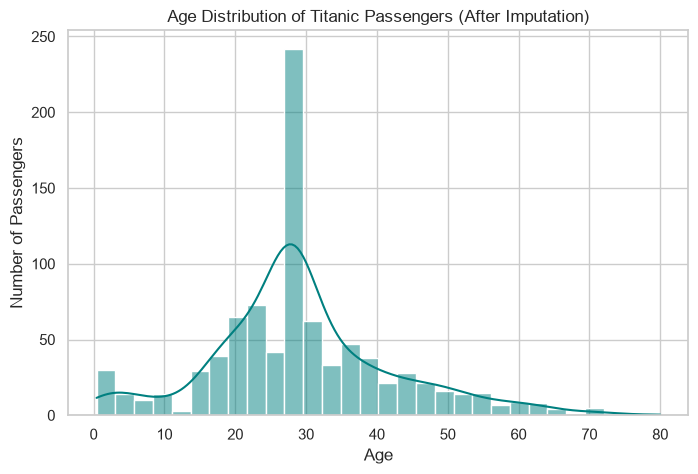

In [13]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Age"], kde=True, bins=30, color='teal')
plt.title("Age Distribution of Titanic Passengers (After Imputation)")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()


### Visualization 2 — Survival Distribution
Shows the class balance of our target variable. We can see that more passengers perished than survived.


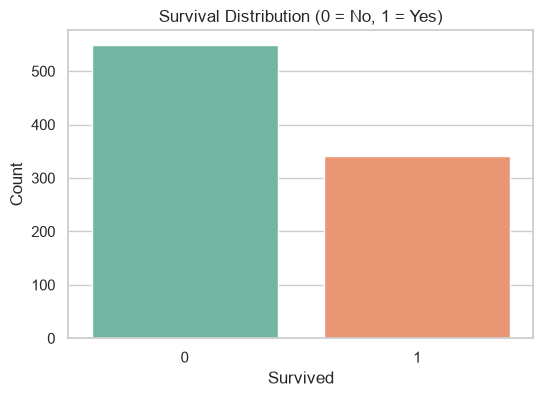

In [14]:
plt.figure(figsize=(6, 4))
sns.countplot(x="Survived", data=df, palette='Set2')
plt.title("Survival Distribution (0 = No, 1 = Yes)")
plt.xlabel("Survived")
plt.ylabel("Count")
plt.show()


### Visualization 3 — Survival by Sex
Since `Sex` is encoded (0=Female, 1=Male), we will map the labels temporarily for a clearer plot.
This shows a stark contrast: females had a much higher survival rate than males.


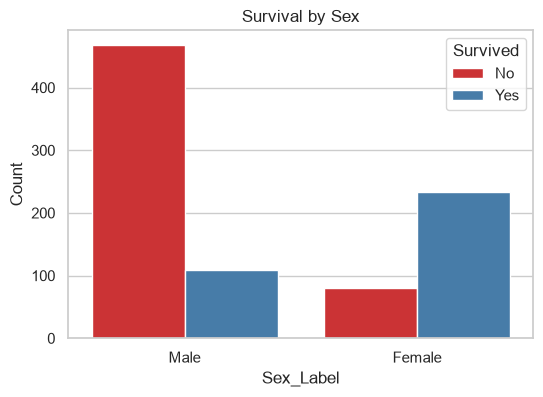

In [15]:
plt.figure(figsize=(6, 4))
df_plot = df.copy()
df_plot['Sex_Label'] = df_plot['Sex'].map({0: 'Female', 1: 'Male'})
sns.countplot(x="Sex_Label", hue="Survived", data=df_plot, palette='Set1')
plt.title("Survival by Sex")
plt.xlabel("Sex_Label")
plt.ylabel("Count")
plt.legend(title='Survived', labels=['No', 'Yes'])
plt.show()


## 14. Correlation Analysis
A correlation matrix helps us understand linear relationships between numerical features and the target.
*Note: Correlation does not imply causation.*


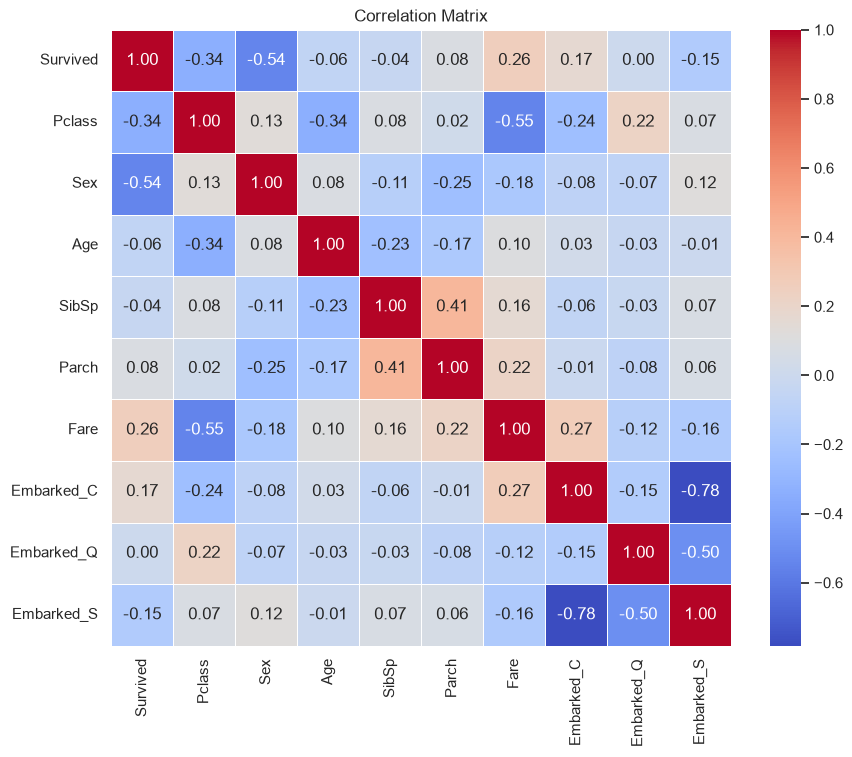

In [16]:
plt.figure(figsize=(10, 8))
# We can drop PassengerId for correlation as it's just an identifier
corr_matrix = df.drop(columns=['PassengerId']).corr(numeric_only=True)
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix")
plt.show()


## 15. Features and Target
Separating the dataset into input features (`X`) and the target label (`y`).
We drop `PassengerId` from `X` because it is an arbitrary identifier and not a meaningful predictive feature.


In [17]:
X = df.drop(columns=["Survived", "PassengerId"])
y = df["Survived"]

print("Features (X):", X.columns.tolist())
print("Target (y): Survived")


Features (X): ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S']
Target (y): Survived


## 16. Train / Test Split
Splitting the data into a training set (80%) and a testing set (20%).
- **Training data** is used to train the machine learning model.
- **Testing data** is kept unseen to evaluate the model's generalization ability.
- **`random_state=42`** ensures reproducibility.
- **`stratify=y`** ensures the Train/Test sets have the same proportion of survivors as the original dataset, which is crucial for imbalanced targets.


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: X={X_train.shape}, y={y_train.shape}")
print(f"Testing set shape: X={X_test.shape}, y={y_test.shape}")


Training set shape: X=(712, 9), y=(712,)
Testing set shape: X=(179, 9), y=(179,)


## 17. ML Model Considerations
*Note on Linear Regression*: While Linear Regression is a fundamental Week 1 concept, it is designed for continuous numerical targets (e.g., predicting house prices).
Our target `Survived` is a **binary classification problem** (0 or 1). Therefore, using Linear Regression here would be inappropriate. The correct approach for this dataset would be a classification algorithm like Logistic Regression. As this project is primarily focused on **Data Cleaning and Preprocessing**, we will conclude the pipeline here without training an arbitrary classification model.


## 18. Data Quality Validation
Running a final audit on our cleaned dataset before export.


In [19]:
print("Final Missing Values Status:")
print(df.isnull().sum())
print("\nFinal Data Types:")
print(df.dtypes)
print("\nFinal Dataset Shape:", df.shape)


Final Missing Values Status:
PassengerId    0
Survived       0
Pclass         0
Sex            0
Age            0
SibSp          0
Parch          0
Fare           0
Embarked_C     0
Embarked_Q     0
Embarked_S     0
dtype: int64

Final Data Types:
PassengerId      int64
Survived         int64
Pclass           int64
Sex              int64
Age            float64
SibSp            int64
Parch            int64
Fare           float64
Embarked_C       int64
Embarked_Q       int64
Embarked_S       int64
dtype: object

Final Dataset Shape: (891, 11)


## 19. Export the Cleaned Dataset
Exporting the fully processed dataset to a new CSV file to preserve the raw `titanic.csv` original file.


In [20]:
df.to_csv("titanic_cleaned.csv", index=False)
print("Successfully saved 'titanic_cleaned.csv'")


Successfully saved 'titanic_cleaned.csv'


## 20. Conclusion
### Summary of Operations:
1. **Dataset Loaded**: Original Titanic dataset was loaded and inspected.
2. **Missing Values Addressed**: 
   - `Age` was imputed using the **median** (robust to skew).
   - `Embarked` was imputed using the **mode**.
   - `Cabin` was dropped due to >70% missing data.
3. **Categorical Encoding**:
   - `Sex` was **Label Encoded** (binary).
   - `Embarked` was **One-Hot Encoded** (nominal).
   - Identifiers (`Name`, `Ticket`) were dropped.
4. **Validation**: The dataset was verified to have 0 missing values, correct numeric types, and appropriate feature columns.
5. **Output**: The clean data was exported as `titanic_cleaned.csv`.

**Next Steps**: The exported dataset is now fully ready for classification algorithms such as Logistic Regression or Decision Trees to predict passenger survival.
